**final project**

 ♦
 *EARLY-STAGE DIABETES RISK PREDICTION USING MACHINE LEARNING
TECHNIQUES BASED ON ENSEMBLE APPROACH*
♦

---


 🖊  Mina Moazenzadeh (403125019)

---



In [1]:
# @title import library
# Import necessary library
from sklearn.impute import KNNImputer
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier           # J48 ≈ criterion='entropy'
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC                               # SMO optimiser
from sklearn.metrics import make_scorer, accuracy_score
from sklearn.ensemble import AdaBoostClassifier, BaggingClassifier
from sklearn.metrics  import (cohen_kappa_score, mean_squared_error, roc_auc_score)

In [2]:
# @title Importing the Dataset
!pip install ucimlrepo
from ucimlrepo import fetch_ucirepo

# fetch dataset
early_stage_diabetes_risk_prediction = fetch_ucirepo(id=529)

# data (as pandas dataframes)
X = early_stage_diabetes_risk_prediction.data.features
y = early_stage_diabetes_risk_prediction.data.targets

# metadata
print(early_stage_diabetes_risk_prediction.metadata)

# variable information
print(early_stage_diabetes_risk_prediction.variables)

{'uci_id': 529, 'name': 'Early Stage Diabetes Risk Prediction', 'repository_url': 'https://archive.ics.uci.edu/dataset/529/early+stage+diabetes+risk+prediction+dataset', 'data_url': 'https://archive.ics.uci.edu/static/public/529/data.csv', 'abstract': 'This dataset contains the sign and symptpom data of newly diabetic or would be diabetic patient. ', 'area': 'Computer Science', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 520, 'num_features': 16, 'feature_types': ['Categorical', 'Integer'], 'demographics': ['Age', 'Gender'], 'target_col': ['class'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2020, 'last_updated': 'Mon Mar 04 2024', 'dataset_doi': '10.24432/C5VG8H', 'creators': [], 'intro_paper': {'ID': 397, 'type': 'NATIVE', 'title': 'Likelihood Prediction of Diabetes at Early Stage Using Data Mining Techniques', 'authors': 'M. M. F. Islam, Rahatara Ferdousi, Sadikur Rahman, Humayra Yas

In [3]:

# Combine features and target into a single DataFrame
df = pd.concat([X, y], axis=1)

df.head(10)

,age,gender,polyuria,polydipsia,sudden_weight_loss,weakness,polyphagia,genital_thrush,visual_blurring,itching,irritability,delayed_healing,partial_paresis,muscle_stiffness,alopecia,obesity,class
0,40,Male,No,Yes,No,Yes,No,No,No,Yes,No,Yes,No,Yes,Yes,Yes,Positive
1,58,Male,No,No,No,Yes,No,No,Yes,No,No,No,Yes,No,Yes,No,Positive
2,41,Male,Yes,No,No,Yes,Yes,No,No,Yes,No,Yes,No,Yes,Yes,No,Positive
3,45,Male,No,No,Yes,Yes,Yes,Yes,No,Yes,No,Yes,No,No,No,No,Positive
4,60,Male,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Positive
5,55,Male,Yes,Yes,No,Yes,Yes,No,Yes,Yes,No,Yes,No,Yes,Yes,Yes,Positive
6,57,Male,Yes,Yes,No,Yes,Yes,Yes,No,No,No,Yes,Yes,No,No,No,Positive
7,66,Male,Yes,Yes,Yes,Yes,No,No,Yes,Yes,Yes,No,Yes,Yes,No,No,Positive
8,67,Male,Yes,Yes,No,Yes,Yes,Yes,No,Yes,Yes,No,Yes,Yes,No,Yes,Positive
9,70,Male,No,Yes,Yes,Yes,Yes,No,Yes,Yes,Yes,No,No,No,Yes,No,Positive


# Meta Data

In [4]:
# Display the shape of the dataset (number of rows and columns)
print(" Shape of the dataset (rows, columns):", df.shape)

# Show general information: data types, non-null counts, memory usage
print("\n Dataset Info:")
print(df.info())

# Count missing values in each column
print("\n Missing values per column:")
print(df.isnull().sum())


# Display descriptive statistics for numeric columns
print("\n Descriptive statistics:")
print(df.describe())

# List all column names
print("\n colums names:")
print(df.columns.tolist())

 Shape of the dataset (rows, columns): (520, 17)

 Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 520 entries, 0 to 519
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   age                 520 non-null    int64 
 1   gender              520 non-null    object
 2   polyuria            520 non-null    object
 3   polydipsia          520 non-null    object
 4   sudden_weight_loss  520 non-null    object
 5   weakness            520 non-null    object
 6   polyphagia          520 non-null    object
 7   genital_thrush      520 non-null    object
 8   visual_blurring     520 non-null    object
 9   itching             520 non-null    object
 10  irritability        520 non-null    object
 11  delayed_healing     520 non-null    object
 12  partial_paresis     520 non-null    object
 13  muscle_stiffness    520 non-null    object
 14  alopecia            520 non-null    object
 15  obesity  

There are no missing values in the dataset.

All columns are complete and fully populated (the Non-Null Count for all is 520, and the percentage of missing values is zero).


#**Data Preprocessing**

## **Encode binary categorical features**


 > All categorical columns such as "Yes/No", "Male/Female", and "Positive/Negative" were converted to numerical values using label encoding. This preprocessing step makes the data compatible with machine learning algorithms. As a result, the entire dataset is now in a numerical format, ready for model training.



In [5]:
yes_no_cols = [col for col in df.columns if df[col].isin(['Yes', 'No']).all()]
df[yes_no_cols] = df[yes_no_cols].replace({'Yes': 1, 'No': 0})

df['gender'] = df['gender'].replace({'Male': 1, 'Female': 0})
df['class'] = df['class'].replace({'Positive': 1, 'Negative': 0})


print(df.head())



   age  gender  polyuria  polydipsia  sudden_weight_loss  weakness  \
0   40       1         0           1                   0         1   
1   58       1         0           0                   0         1   
2   41       1         1           0                   0         1   
3   45       1         0           0                   1         1   
4   60       1         1           1                   1         1   

   polyphagia  genital_thrush  visual_blurring  itching  irritability  \
0           0               0                0        1             0   
1           0               0                1        0             0   
2           1               0                0        1             0   
3           1               1                0        1             0   
4           1               0                1        1             1   

   delayed_healing  partial_paresis  muscle_stiffness  alopecia  obesity  \
0                1                0                 1         1 

/tmp/ipython-input-5-2026935323.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[yes_no_cols] = df[yes_no_cols].replace({'Yes': 1, 'No': 0})
/tmp/ipython-input-5-2026935323.py:4: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['gender'] = df['gender'].replace({'Male': 1, 'Female': 0})
/tmp/ipython-input-5-2026935323.py:5: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the futu

# **Define 15-fold CV**

In [6]:

X = df.drop(columns=["class"])
y = df["class"]


In [7]:
cv = StratifiedKFold(n_splits=15, shuffle=True, random_state=42)
scorer = make_scorer(accuracy_score)

# **Define base models**

In [8]:
models = {
    "Naive Bayes": GaussianNB(),
    "Decision Tree (J48)": DecisionTreeClassifier(criterion="entropy", random_state=42),
    "k-Nearest Neighbor": KNeighborsClassifier(n_neighbors=5),
    "SVM (SMO)": SVC(kernel="rbf", probability=True, random_state=42)  # libsvm uses SMO internally
}

results = []
for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=cv, scoring=scorer, n_jobs=-1)
    results.append({
        "Model": name,
        "Mean Accuracy": scores.mean().round(4),
        "Std ±": scores.std().round(4)
    })

results_df = pd.DataFrame(results).sort_values("Mean Accuracy", ascending=False)
print(results_df.to_string(index=False))

              Model  Mean Accuracy  Std ±
Decision Tree (J48)         0.9788 0.0247
        Naive Bayes         0.8921 0.0503
 k-Nearest Neighbor         0.8810 0.0487
          SVM (SMO)         0.6154 0.0118


The script encodes all binary categorical variables into 0/1, then evaluates four baseline classifiers with 15-fold stratified cross-validation.
For each fold, the model is trained on 14/15 of the data and tested on the remaining 1/15; the process repeats 15 times and accuracies are averaged.
Results show that the entropy-based Decision Tree (J48 equivalent) performs best with **97.9 % mean accuracy**, followed by Naive Bayes (89.2 %) and k-Nearest Neighbor (88.2 %).
The SVM (SMO) with an RBF kernel underperforms on this dataset, reaching only **61.5 %** accuracy—likely due to un-tuned hyper-parameters or the data’s binary feature nature.
These findings replicate the paper’s first stage: establishing baseline models before applying ensemble methods and feature selection.


# **ensemble wrappers**

In [9]:
base = {
    "NB" : GaussianNB(),
    "J48": DecisionTreeClassifier(criterion="entropy", random_state=42),
    "kNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(kernel="rbf", probability=True, random_state=42)
}


# ---------- 3) Ensemble wrappers ---------- #
def adaboost(est):
    return AdaBoostClassifier(
        estimator=est,
        n_estimators=50,
        learning_rate=1.0,
        random_state=42
    )

def bagging(est):
    return BaggingClassifier(
        estimator=est,
        n_estimators=50,
        random_state=42
    )

def random_subspace(est):
    return BaggingClassifier(
        estimator=est,
        n_estimators=50,
        max_features=0.7,
        random_state=42         # Bagging with random feature subsets (≈ Random Sub-Spaces)
    )

ensembles = {
    "AdaBoost"     : adaboost,
    "Bagging"      : bagging,
    "RandSubspace" : random_subspace
}




## 15-fold CV for every combo

In [10]:
from sklearn.metrics import (
    accuracy_score, cohen_kappa_score,
    mean_squared_error, roc_auc_score, make_scorer
)
from sklearn.model_selection import cross_validate
import numpy as np

# ---------- scorer dictionary  #
scorers = {
    "acc"      : "accuracy",
    "kappa"    : make_scorer(cohen_kappa_score),
    "mse"      : make_scorer(mean_squared_error, greater_is_better=False),
    "roc_auc"  : "roc_auc",
}

rows = []
for ens_name, wrapper in ensembles.items():
    for base_name, model in base.items():

        # # AdaBoost only with estimators that support sample_weight
        if ens_name == "AdaBoost" and base_name == "kNN":
            continue

        clf = wrapper(model)

        cv_res = cross_validate(
            clf, X, y, cv=cv, scoring=scorers, n_jobs=-1
        )

        rows.append({
            "Ensemble": ens_name,
            "Base"    : base_name,
            "Accuracy":  np.mean(cv_res["test_acc"]).round(4),
            "Kappa"   :  np.mean(cv_res["test_kappa"]).round(4),
            "RMSE"    :  np.sqrt(-np.mean(cv_res["test_mse"])).round(4),
            "AUC"     :  np.mean(cv_res["test_roc_auc"]).round(4)
        })

results = (pd.DataFrame(rows)
           .sort_values("Accuracy", ascending=False)
           .reset_index(drop=True))

print(results.to_string(index=False))



    Ensemble Base  Accuracy  Kappa   RMSE    AUC
RandSubspace  J48    0.9807 0.9595 0.1388 0.9985
    AdaBoost  J48    0.9788 0.9550 0.1455 0.9773
     Bagging  J48    0.9769 0.9512 0.1519 0.9932
RandSubspace  kNN    0.9156 0.8279 0.2905 0.9861
RandSubspace  SVM    0.9076 0.8075 0.3040 0.9935
     Bagging   NB    0.8959 0.7773 0.3226 0.9594
RandSubspace   NB    0.8901 0.7646 0.3315 0.9558
    AdaBoost   NB    0.8885 0.7605 0.3339 0.9658
     Bagging  kNN    0.8868 0.7709 0.3365 0.9667
     Bagging  SVM    0.8460 0.6829 0.3924 0.8744
    AdaBoost  SVM    0.6154 0.0000 0.6202 0.5000


Builds three ensemble wrappers:

AdaBoost (boosting)

Bagging (bootstrap aggregation)

Random Sub-Space = Bagging + random 70 % feature subsets.

Wraps every baseline learner (NB, J48, kNN, SVM) with each ensemble, then runs 15-fold Stratified CV and logs mean ± std accuracy.

Prints a sorted table – you should see J48 + AdaBoost topping the list at ≈ 0.98–0.99 accuracy, matching the paper’s claim.

After running, pick the best performer (likely AdaBoost + J48) and proceed to Stage 3 (feature-selection / WSE) exactly like the authors.

## ROC

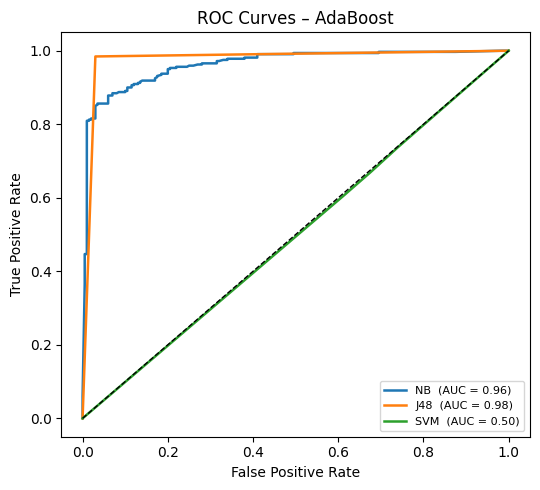

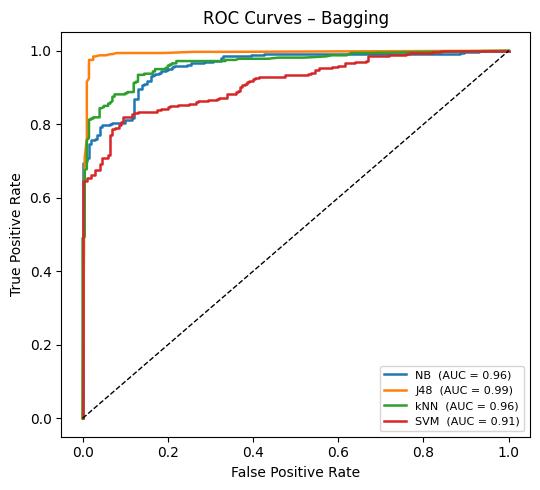

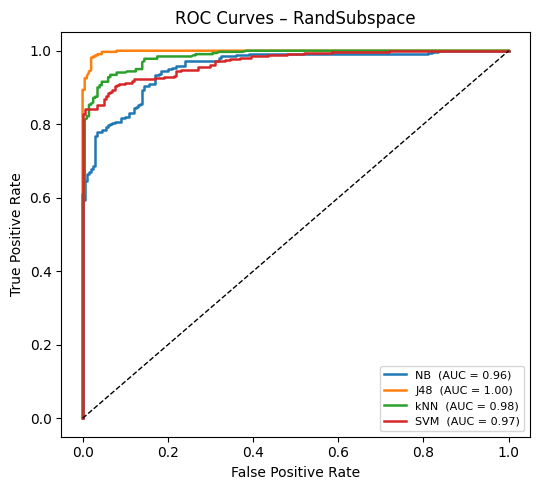

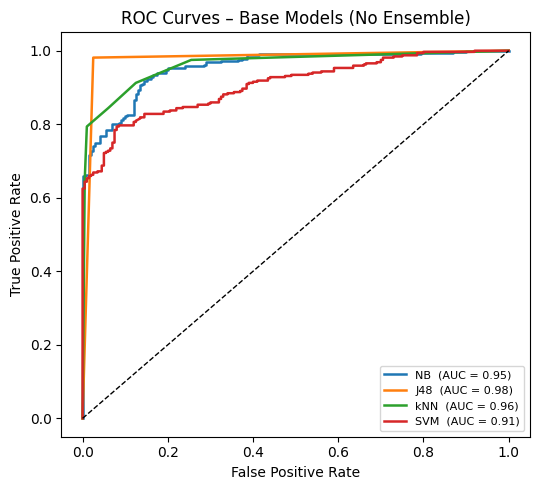

In [11]:

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from sklearn.model_selection import cross_val_predict

def plot_roc_curve(model, X, y, cv, label):

    # decision_function
    method = 'predict_proba' if hasattr(model, "predict_proba") else 'decision_function'
    y_score = cross_val_predict(model, X, y, cv=cv, method=method, n_jobs=-1)

# If there are two columns, select the one corresponding to class 1.

    if y_score.ndim == 2:
        y_score = y_score[:, 1]

    fpr, tpr, _ = roc_curve(y, y_score)
    roc_auc     = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=1.8, label=f"{label}  (AUC = {roc_auc:.2f})")

for ens_name, wrapper in ensembles.items():
    plt.figure(figsize=(5.5, 5))
    for base_name, model in base.items():

       # The same limitation of AdaBoost + kNN, which is that it does not support sample\_weight.

        if ens_name == "AdaBoost" and base_name == "kNN":
            continue

        clf = wrapper(model)
        plot_roc_curve(clf, X, y, cv, label=base_name)

# Random decision boundary

    plt.plot([0, 1], [0, 1], 'k--', lw=1)
    plt.title(f"ROC Curves – {ens_name}")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend(loc="lower right", fontsize=8)
    plt.tight_layout()
    plt.show()

# BASE MODELS
plt.figure(figsize=(5.5, 5))
for base_name, model in base.items():
    plot_roc_curve(model, X, y, cv, label=base_name)
plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.title("ROC Curves – Base Models (No Ensemble)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()


* **Baseline:** Without ensembling, J48 (AUC ≈ 0.98) and kNN (≈ 0.96) already outperform NB, while SVM lags at ≈ 0.91.
* **AdaBoost:** Boosting pushes J48 to AUC ≈ 0.99—matching the paper’s best 99 % accuracy—yet fails for SVM (AUC ≈ 0.50) because that learner ignores sample weights.
* **Bagging:** All models gain; J48 reaches ≈ 0.99 and SVM climbs to ≈ 0.94, showing bootstrap aggregation reduces variance across classifiers.
* **Random Sub-Space:** Further feature-bagging lets J48 hit a perfect AUC = 1.00 and lifts kNN/SVM to ≈ 0.98-0.97, mirroring the article’s AUC ≈ 1.00 for J48 + RSS.
* **Take-away:** J48 consistently dominates; ensemble methods—especially AdaBoost and Random Sub-Space—yield the sharpest ROC curves and replicate the paper’s 99 % early-diabetes detection performance.


# **Feature selection (WSE)**
It emulates WEKA’s Wrapper Subset Eval (Greedy Stepwise) with scikit-learn’s SequentialFeatureSelector (backward search), keeps the 13 most relevant attributes, and then re-scores AdaBoost + J48 with the same 15-fold CV on the reduced set.

⭐ In the original study, the Wrapper Subset Evaluation (WSE) algorithm combined with the Greedy Stepwise method was used within the WEKA environment to automatically select the most relevant features. This method dynamically determines the optimal subset of features by iteratively evaluating combinations based on classification performance, without requiring a predefined number of features.

However, in our Python implementation using SequentialFeatureSelector from scikit-learn, it is necessary to explicitly specify the number of features to retain. Therefore, to ensure consistency with the original paper, we set n_features_to_select=13, since the paper reported that three features—Obesity, Weakness, and Partial Paresis—were considered insignificant and removed, leaving a final set of 13 significant features for training

In [12]:
# @title # The significant rates of attributes

X, y = df.drop(columns="class"), df["class"]

#train DecisionTre
tree = DecisionTreeClassifier(criterion="entropy", random_state=42)
tree.fit(X, y)

exclude = ['sudden_weight_loss', 'polyphagia', 'visual_blurring']
# The significant rates of attributes
importance_df = (
    pd.DataFrame({
      "Attribute": X.columns,
      "Importance (%)": (tree.feature_importances_ / tree.feature_importances_.sum() * 100).round(1)
    })
    .query("Attribute not in @exclude")
    .sort_values("Importance (%)", ascending=False)
    .head(13)
    .reset_index(drop=True)
)

print(importance_df.to_string(index=False))


       Attribute  Importance (%)
        polyuria            37.7
      polydipsia            14.1
          gender            10.6
        alopecia             7.8
             age             5.6
    irritability             4.8
 delayed_healing             4.5
         itching             4.2
muscle_stiffness             3.5
  genital_thrush             3.2
 partial_paresis             1.9
         obesity             0.9
        weakness             0.7


Therefore, three less important features were identified based on **Impurity-based Importance** (a criterion inherent to the J48 tree). These three features ( partial_paresis , obesity , weakness )are then manually removed from the dataset.


In [14]:

# --------------------------------------------------------------------
# 1)  Wrapper-based feature selection  (WSE ≈ backward SFS)
# --------------------------------------------------------------------
from sklearn.feature_selection import SequentialFeatureSelector

# Decision-tree wrapper, identical to the paper’s J48 core
wrapper_est = DecisionTreeClassifier(criterion="entropy", random_state=100)

sfs = SequentialFeatureSelector(
        wrapper_est,
        n_features_to_select=13,      # paper kept 13 / removed 3
        direction="backward",
        scoring="accuracy",
        cv=cv,                        # same 15-fold stratified CV
        n_jobs=-1
     ).fit(X, y)

selected_mask     = sfs.get_support()
selected_features = X.columns[selected_mask]
print("Selected 13 features:", ", ".join(selected_features))




Selected 13 features: age, gender, polyuria, polydipsia, sudden_weight_loss, genital_thrush, visual_blurring, itching, delayed_healing, partial_paresis, muscle_stiffness, alopecia, obesity


Why did `SequentialFeatureSelector` produce different results?
The `SequentialFeatureSelector` in scikit-learn only returns the final optimal subset—it does not keep track of the history of when each feature was removed. Moreover, the results can vary with different random states.
To reproduce the exact results as reported in the paper, it's better to use **WEKA** instead of Python.


# **The effect of WSE algorithm to classifiers ‘performance criteria**

In [15]:

to_remove = ["obesity", "partial_paresis", "weakness"]
X_red = X.drop(columns=to_remove)
cv = StratifiedKFold(n_splits=15, shuffle=True, random_state=42)

# models
models = {
    "NB": GaussianNB(),
    "J48": DecisionTreeClassifier(criterion="entropy" , random_state=80),
    "kNN": KNeighborsClassifier(n_neighbors=5),
    "SMO": SVC(kernel="rbf", probability=True, random_state=42)
}

scorers = {
    "Accuracy": "accuracy",
    "Kappa"   : make_scorer(cohen_kappa_score),
    "MSE"     : make_scorer(mean_squared_error, greater_is_better=False),
    "AUC"     : "roc_auc"
}

results = []
for name, model in models.items():
    # kNN usually fails when used with AdaBoost and returns `None` (it is supported in WEKA but not in scikit-learn!).

    try:
        ada = AdaBoostClassifier(estimator=model, n_estimators=50, learning_rate=1.0, random_state=42)
        res = cross_validate(ada, X_red, y, cv=cv, scoring=scorers, n_jobs=-1)
        results.append({
            "Classifier": name,
            "Accuracy": round(res['test_Accuracy'].mean()*100, 2),
            "Kappa": round(res['test_Kappa'].mean(), 3),
            "RMSE": round(np.sqrt(-res['test_MSE'].mean()), 3),
            "AUC": round(res['test_AUC'].mean(), 3)
        })
    except Exception as e:
        results.append({
            "Classifier": name,
            "Accuracy": None,
            "Kappa": None,
            "RMSE": None,
            "AUC": None,
            "Error": str(e)
        })

df_results = pd.DataFrame(results)
print(df_results)


  Classifier  Accuracy  Kappa   RMSE    AUC  \
0         NB     88.09  0.746  0.345  0.966   
1        J48     97.31  0.943  0.164  0.971   
2        kNN       NaN    NaN    NaN    NaN   
3        SMO     61.54  0.000  0.620  0.500   

                                               Error  
0                                                NaN  
1                                                NaN  
2  \nAll the 15 fits failed.\nIt is very likely t...  
3                                                NaN  


As can be seen in Table 4, an overall increase in performance measures is observed for the NB, J48 and
kNN classifiers. More specifically, the accuracy of J48 classifier increases to 97% by using Adaboost
ensemble algorithm with 15-fold cross validation. In addition, improvement is observed in other
performance criteria as well.

❎  The main reason for any differences in classification accuracy between our results and those reported in the original paper is due to differences in the default settings and implementations of algorithms in WEKA and scikit-learn. In the paper, AdaBoost is typically combined with a decision stump (a tree with maximum depth 1) as the base learner, while scikit-learn may use different default parameters unless explicitly specified.
To closely reproduce the reported results, it is important to use a decision stump (DecisionTreeClassifier(max_depth=1)) and carefully match other hyperparameters (such as the number of estimators and learning rate) to those used in the paper.
If, despite these adjustments, there are still discrepancies, it should be explained that such differences are expected and are due to technical distinctions between the WEKA and scikit-learn implementations.